**Nome:** Salvador Franco Sequeira · **Número:** 53912

**Nome:** Ricardo Costa · **Número:** 53732

**Data:** 12/11/2026

# Projeto Final · LusoEnergia
## Parte I - Fundação (Checkpoint 1)

Para o Checkpoint 1: dados carregados e tipados (1.1) e auditoria de qualidade esboçada (1.2). O sumário estatístico (1.3) fica para o Checkpoint 2.

# Preparação

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Rectangle
from math import comb

from src.dados import (FICHEIRO, carregar_dados, recortar, validar, janela_do_grupo,
                       lacunas, tratar_lacunas, consumo_diario)

NUMEROS = [53912, 53732]
SEED = sum(NUMEROS)
JANELA = janela_do_grupo(SEED)
inicio, fim = JANELA
DIAS = ['segunda', 'terça', 'quarta', 'quinta', 'sexta', 'sábado', 'domingo']

print(f'Seed = {SEED}')
print(f'Janela: {inicio:%d/%m/%Y} a {fim - pd.Timedelta(minutes=1):%d/%m/%Y %H:%M} ({fim:%d/%m/%Y} já fica de fora)')

Seed = 107644
Janela: 01/02/2008 a 31/07/2009 23:59 (01/08/2009 já fica de fora)


R.: A janela do grupo vai de 1 de fevereiro de 2008 a 31 de julho de 2009: 547 dias, 787 680 minutos. Tratamos a janela como intervalo semiaberto [início, fim), para ter exatamente 18 meses sem o primeiro minuto de agosto. A janela cobre um inverno completo (2008/09) e o fim de outro (fevereiro de 2008), o verão de 2008 e junho e julho de 2009. Os meses de fevereiro a julho aparecem duas vezes e os de agosto a janeiro só uma, o que convém lembrar quando se falar de sazonalidade anual, sobretudo em agosto, o mês típico de férias em França.

# 1.1 Carregamento e tipagem

**1.1)** Construir uma função `carregar_dados()` que lê o ficheiro bruto e devolve um DataFrame com índice temporal (`DatetimeIndex`), dtypes justificados variável a variável (dicionário de dados com a escala de medida de Stevens de cada coluna) e sentinelas `'?'` convertidas. Mínimo de 5 asserts de validação.

In [2]:
# a) O ficheiro bruto

with open(FICHEIRO, encoding='utf-8') as f:
    print(''.join(next(f) for _ in range(3)))

with open(FICHEIRO, encoding='utf-8') as f:
    falhas = [linha for linha in f if '?' in linha]

print(falhas[0])
print(f'Linhas com "?": {len(falhas)}')

Date;Time;Global_active_power;Global_reactive_power;Voltage;Global_intensity;Sub_metering_1;Sub_metering_2;Sub_metering_3
16/12/2006;17:24:00;4.216;0.418;234.840;18.400;0.000;1.000;17.000
16/12/2006;17:25:00;5.360;0.436;233.630;23.000;0.000;1.000;16.000

21/12/2006;11:23:00;?;?;?;?;?;?;

Linhas com "?": 25979


R.: O ficheiro tem extensão .csv, mas o separador é `;`. A data e a hora vêm em duas colunas de texto, com a data no formato dia/mês/ano: sem `format` explícito, o pandas pode ler 1/2/2007 como 2 de janeiro. As leituras em falta têm `?` em seis colunas, mas a última (Sub_metering_3) vem vazia, por isso há duas sentinelas: `?` e o campo vazio. São 25 979 linhas de falha.

In [3]:
# b) Carregamento

%time completo = carregar_dados()
df = recortar(completo, JANELA)

print(f'Completo: {len(completo)} linhas, de {completo.index[0]} a {completo.index[-1]}')
print(f'Janela:   {len(df)} linhas, de {df.index[0]} a {df.index[-1]}')
print(f'Linhas sem leitura no completo: {completo.isna().all(axis=1).sum()} (linhas com "?" no bruto: {len(falhas)})')
print()
df.info()

memoria = pd.Series({'float32': completo.memory_usage(deep=True).sum(),
                     'float64': completo.astype('float64').memory_usage(deep=True).sum()}) / 1e6
print()
print('Memória do conjunto completo (MB):', memoria.round(1).to_dict())

CPU times: total: 3.78 s
Wall time: 3.69 s
Completo: 2075259 linhas, de 2006-12-16 17:24:00 a 2010-11-26 21:02:00
Janela:   787680 linhas, de 2008-02-01 00:00:00 a 2009-07-31 23:59:00
Linhas sem leitura no completo: 25979 (linhas com "?" no bruto: 25979)

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 787680 entries, 2008-02-01 00:00:00 to 2009-07-31 23:59:00
Data columns (total 7 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Global_active_power    784164 non-null  float32
 1   Global_reactive_power  784164 non-null  float32
 2   Voltage                784164 non-null  float32
 3   Global_intensity       784164 non-null  float32
 4   Sub_metering_1         784164 non-null  float32
 5   Sub_metering_2         784164 non-null  float32
 6   Sub_metering_3         784164 non-null  float32
dtypes: float32(7)
memory usage: 43.2 MB

Memória do conjunto completo (MB): {'float32': 142.3, 'float64': 200.4}


R.: A função `carregar_dados()` está em `src/dados.py`, porque vai ser usada em todas as partes e no dashboard. Faz três coisas:

1. Lê o ficheiro com `sep=';'`, `na_values=['?', '']` e `keep_default_na=False`: só estes dois códigos passam a NaN. As 7 colunas numéricas são lidas diretamente como float32, por isso qualquer outro texto inesperado faria o `read_csv` falhar, em vez de deixar a coluna como texto sem avisar.
2. Constrói o índice com `to_datetime(Date, format='%d/%m/%Y') + to_timedelta(Time)`, vetorizado e com o formato explícito.
3. Chama `validar(df)`, que corre os asserts (ver d). `recortar()` volta a validar depois de cortar a janela.

As 25 979 linhas com `?` no ficheiro bruto são exatamente as 25 979 linhas sem leitura no DataFrame, por isso todas as sentinelas foram convertidas. A leitura completa demora menos de meio minuto; ponderámos guardar um parquet intermédio, como sugere o enunciado, mas com este tempo não compensa o risco de trabalhar com uma cópia desatualizada. O ficheiro bruto fica intocado e é sempre a fonte.

In [4]:
# c) Dicionário de dados

dicionario = pd.DataFrame([
    ('instante (índice)', 'data e hora da leitura (Date + Time)', '-', 'intervalar', 'datetime64[us]',
     'permite resample, janelas e filtros por data; sem fuso horário (ver e)'),
    ('Global_active_power', 'potência ativa média no minuto', 'kW', 'razão', 'float32',
     'contínua, 3 casas decimais: os 7 algarismos significativos do float32 chegam'),
    ('Global_reactive_power', 'potência reativa média no minuto', 'kW (rigorosamente kvar)', 'razão', 'float32',
     'contínua, 3 casas decimais; muitas leituras a 0'),
    ('Voltage', 'tensão média no minuto', 'V', 'razão', 'float32',
     'contínua, 2 casas decimais'),
    ('Global_intensity', 'intensidade de corrente média no minuto', 'A', 'razão', 'float32',
     'múltiplos de 0,2 A (resolução do aparelho)'),
    ('Sub_metering_1', 'energia ativa da cozinha (máq. loiça, forno, micro-ondas)', 'Wh no minuto', 'razão', 'float32',
     'contador inteiro; float32 e não Int16 porque tem NaN (ver R.)'),
    ('Sub_metering_2', 'energia ativa da lavandaria (máq. roupa, secador, frigorífico, luz)', 'Wh no minuto', 'razão', 'float32',
     'idem'),
    ('Sub_metering_3', 'energia ativa do termoacumulador e do ar condicionado', 'Wh no minuto', 'razão', 'float32',
     'idem'),
], columns=['variavel', 'descricao', 'unidade', 'escala_Stevens', 'dtype', 'justificacao']).set_index('variavel')

estatisticas = completo.agg(['min', 'max']).T.round(3)
estatisticas['distintos'] = completo.nunique()
estatisticas['%_zeros'] = (100 * (completo == 0).mean()).round(1)
dicionario.join(estatisticas)

,descricao,unidade,escala_Stevens,dtype,justificacao,min,max,distintos,%_zeros
variavel,,,,,,,,,
instante (índice),data e hora da leitura (Date + Time),-,intervalar,datetime64[us],"permite resample, janelas e filtros por data; ...",NaN,NaN,NaN,NaN
Global_active_power,potência ativa média no minuto,kW,razão,float32,"contínua, 3 casas decimais: os 7 algarismos si...",0.076,11.122,4186.0,0.0
Global_reactive_power,potência reativa média no minuto,kW (rigorosamente kvar),razão,float32,"contínua, 3 casas decimais; muitas leituras a 0",0.000,1.390,532.0,23.2
Voltage,tensão média no minuto,V,razão,float32,"contínua, 2 casas decimais",223.200,254.150,2837.0,0.0
Global_intensity,intensidade de corrente média no minuto,A,razão,float32,"múltiplos de 0,2 A (resolução do aparelho)",0.200,48.400,221.0,0.0
Sub_metering_1,"energia ativa da cozinha (máq. loiça, forno, m...",Wh no minuto,razão,float32,contador inteiro; float32 e não Int16 porque t...,0.000,88.000,88.0,90.6
Sub_metering_2,"energia ativa da lavandaria (máq. roupa, secad...",Wh no minuto,razão,float32,idem,0.000,80.000,81.0,69.2
Sub_metering_3,energia ativa do termoacumulador e do ar condi...,Wh no minuto,razão,float32,idem,0.000,31.000,32.0,41.1


R.: Todas as variáveis numéricas são de razão: têm um zero com significado físico (sem potência, sem corrente, sem energia) e faz sentido dizer que um valor é o dobro de outro. A tensão é um caso-limite: o zero existe fisicamente, mas os valores vivem numa banda estreita (223 a 254 V) à volta do nominal, e o que interessa são os desvios, não as razões. O índice é intervalar: a origem do calendário é convencional, por isso a diferença entre dois instantes tem significado, mas a razão não.

As unidades exigem atenção: a potência é uma média no minuto em kW e as submedições são energia em Wh nesse minuto. A ponte é energia (Wh) = potência (kW) × 1000 / 60, e o consumo diário em kWh é a média da potência no dia × 24 h. Esquecer a divisão por 60 multiplica a energia por 60; confundir W com kW, por 1000.

Escolhemos float32 em vez do float64 por omissão: os dados têm no máximo três casas decimais em valores abaixo de 260, muito dentro dos 7 algarismos significativos do float32, e a memória do conjunto completo cai de 132,8 para 74,7 MB. O custo é que somas sobre centenas de milhares de minutos acumulam erro de arredondamento em float32, por isso as agregações convertem primeiro para float64: já o fazemos em `consumo_diario()` e vamos fazê-lo na verificação do Welford na Parte IV. As submedições são inteiras, mas guardá-las como `Int16` (inteiro com NA) pouparia pouca memória (3 bytes por valor, contando a máscara de NA, contra 4) e obrigaria a converter o `pd.NA` sempre que passassem por numpy, sklearn ou river; o float32 representa exatamente todos os inteiros até 16 milhões.

**d) Asserts de validação** (em `validar()`, chamada por `carregar_dados()` e `recortar()`)

| # | Assert | Porquê |
|---|---|---|
| 1 | o índice é `DatetimeIndex` | resample, janelas e filtros por data dependem dele |
| 2 | índice único e ordenado | instantes repetidos contariam consumo duas vezes; fora de ordem estragam as janelas deslizantes e o replay da Parte IV |
| 3 | passos de exatamente 1 minuto | cada falha é uma linha NaN visível, e não um minuto que simplesmente não existe |
| 4 | todas as variáveis em float32 | confirma que nenhuma coluna ficou como texto por causa das sentinelas |
| 5 | falta tudo ou nada em cada linha | a falha é do registo e não de um sensor; é a base do argumento sobre o mecanismo em 1.2 |
| 6 | potências, intensidade e energias ≥ 0 | uma casa só consome; um negativo seria erro de leitura ou de sinal |
| 7 | tensão entre 200 e 260 V | rede de 230 V; fora disto a unidade está errada (kV, mV) ou há colunas trocadas |
| 8 | submedições inteiras | são contadores em Wh; decimais indicariam outra unidade |
| 9 | soma das submedições ≤ energia total do minuto + 3 Wh | uma parte da casa não pode gastar mais do que a casa toda; os 3 Wh cobrem o arredondamento dos três contadores inteiros (até 1 Wh cada) |
| 10 | I ≈ √(P² + Q²) × 1000 / V, com erro mediano < 0,2 A | confirma as unidades kW, V e A em conjunto: com a potência em W o erro seria mil vezes maior |

Os dados reais passam os 10 (a célula de carregamento correu sem erro). Para mostrar que os asserts não passam tudo, damos-lhes versões estragadas de propósito:

In [5]:
# d) Os asserts apanham erros?

estragados = {
    'tensão em kV': df.assign(Voltage=df['Voltage'] / 1000),
    'potência em W': df.assign(Global_active_power=df['Global_active_power'] * 1000),
    'minuto repetido': pd.concat([df.iloc[:1], df]),
    'minuto sem linha': df.drop(df.index[100]),
    'falta parcial': df.assign(Voltage=df['Voltage'].where(df.index != df.index[0])),
}

for nome, versao in estragados.items():
    try:
        validar(versao)
        print(f'{nome:17} -> passou sem erro')
    except AssertionError as erro:
        print(f'{nome:17} -> apanhado: {erro}')

tensão em kV      -> apanhado: tensão fora de 200 a 260 V (unidade errada?)
potência em W     -> apanhado: I diferente de S/V: unidades incoerentes
minuto repetido   -> apanhado: índice com instantes repetidos ou fora de ordem
minuto sem linha  -> apanhado: grelha de 1 min com buracos: há minutos sem linha
falta parcial     -> apanhado: linha com falta parcial (esperado: tudo ou nada)


R.: As cinco versões estragadas são todas apanhadas, cada uma pelo assert correspondente. A potência em W passa os testes de sinal e de balanço de energia: o balanço (assert 9) só limita as submedições por cima, e uma potência mil vezes maior continua a respeitá-lo. Só a coerência I = S/V (assert 10) a apanha.

In [6]:
# e) O relógio muda de hora?

mudancas_hora = pd.to_datetime(['2008-03-30', '2008-10-26', '2009-03-29'])
df.groupby(df.index.normalize()).size().loc[mudancas_hora].to_frame('minutos_no_dia')

,minutos_no_dia
2008-03-30,1440
2008-10-26,1440
2009-03-29,1440


R.: Nos três dias de mudança de hora da janela há exatamente 1440 minutos, e não 1380 ou 1500, e o assert 3 garante o mesmo nos quatro anos. O relógio do registador não segue a hora legal de verão, por isso deixamos o índice sem fuso horário (tz-naive). Isto tem uma consequência para a Parte II: não sabemos em que fuso está o relógio, e no verão a hora registada pode estar desfasada uma hora da hora legal francesa. Um pico às 7 h no verão pode ser às 8 h na vida da família.

# 1.2 Auditoria de qualidade (esboço)

**1.2)** Quantificar os valores em falta por variável e por período (encontrar os dias inteiros sem leituras e visualizá-los num calendário), classificar o mecanismo provável (MCAR/MAR/MNAR) com argumentação e justificar a estratégia de tratamento, que tem de ser diferente para lacunas de 1 minuto e de 2 dias.

In [7]:
# a) Falta por variável

falta = pd.DataFrame({'completo': completo.isna().sum(), 'janela': df.isna().sum()})
falta['completo_%'] = (100 * falta['completo'] / len(completo)).round(2)
falta['janela_%'] = (100 * falta['janela'] / len(df)).round(2)
falta

,completo,janela,completo_%,janela_%
Global_active_power,25979,3516,1.25,0.45
Global_reactive_power,25979,3516,1.25,0.45
Voltage,25979,3516,1.25,0.45
Global_intensity,25979,3516,1.25,0.45
Sub_metering_1,25979,3516,1.25,0.45
Sub_metering_2,25979,3516,1.25,0.45
Sub_metering_3,25979,3516,1.25,0.45


R.: As sete variáveis têm exatamente o mesmo número de valores em falta: 25 979 minutos (1,25 %) no conjunto completo e 3 516 (0,45 %) na nossa janela. Com o assert 5, isto mostra que não há falhas de um sensor isolado: quando falta, falta a linha inteira. A auditoria por variável esgota-se aqui e o resto é sobre o tempo. A nossa janela é relativamente limpa: tem pouco mais de um terço da taxa de falta do conjunto completo.

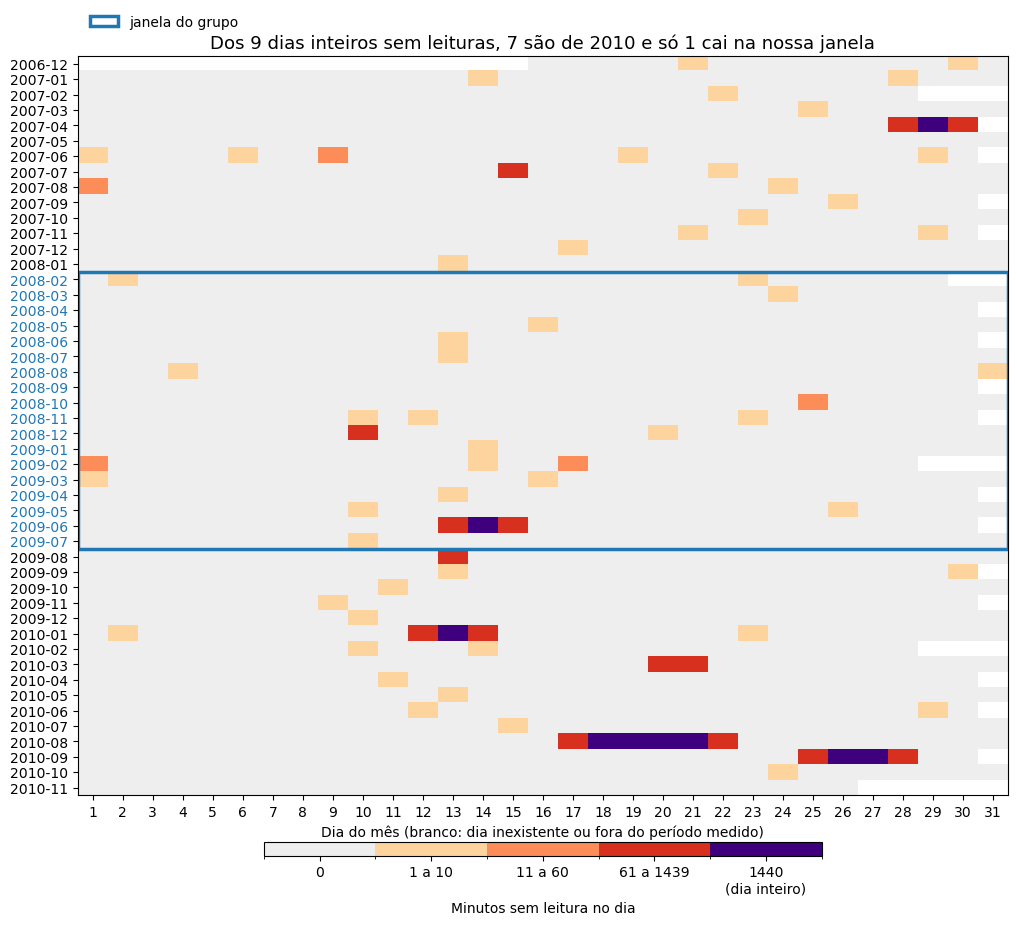

In [8]:
# b) Falta por período: calendário

minutos_falta = completo['Global_active_power'].isna().resample('D').sum()
calendario = (minutos_falta.to_frame('minutos')
              .assign(mes=lambda d: d.index.strftime('%Y-%m'), dia=lambda d: d.index.day)
              .pivot(index='mes', columns='dia', values='minutos'))

limites = [-0.5, 0.5, 10.5, 60.5, 1439.5, 1440.5]
classes = ['0', '1 a 10', '11 a 60', '61 a 1439', '1440\n(dia inteiro)']
cores = ListedColormap(['#eeeeee', '#fdd49e', '#fc8d59', '#d7301f', '#3f007d'])
meses_janela = np.flatnonzero((calendario.index >= f'{inicio:%Y-%m}') & (calendario.index < f'{fim:%Y-%m}'))

fig, ax = plt.subplots(figsize=(12, 12))
im = ax.imshow(calendario, cmap=cores, norm=BoundaryNorm(limites, cores.N), aspect='auto')
moldura = Rectangle((-0.5, meses_janela[0] - 0.5), 31, len(meses_janela),
                    fill=False, edgecolor='tab:blue', lw=2.5, label='janela do grupo')
ax.add_patch(moldura)
ax.set_xticks(range(31), range(1, 32))
ax.set_yticks(range(len(calendario)), calendario.index)
for i in meses_janela:
    ax.get_yticklabels()[i].set_color('tab:blue')
ax.set_xlabel('Dia do mês (branco: dia inexistente ou fora do período medido)')
ax.set_title('Dos 9 dias inteiros sem leituras, 7 são de 2010 e só 1 cai na nossa janela', fontsize=13)
ax.legend(handles=[moldura], loc='lower left', bbox_to_anchor=(0, 1.02), frameon=False)
barra = fig.colorbar(im, ax=ax, location='bottom', ticks=[0, 5.5, 35.5, 750, 1440], shrink=0.6, aspect=40, pad=0.05)
barra.set_ticklabels(classes)
barra.set_label('Minutos sem leitura no dia')
plt.show()

In [9]:
dias_sem_leitura = minutos_falta[minutos_falta == 1440].to_frame('minutos')
dias_sem_leitura['dia_semana'] = [DIAS[d] for d in dias_sem_leitura.index.dayofweek]
dias_sem_leitura['na_janela'] = (dias_sem_leitura.index >= inicio) & (dias_sem_leitura.index < fim)
display(dias_sem_leitura)

falhas_longas = lacunas(completo).query('minutos >= 1440').assign(dias=lambda d: (d['minutos'] / 1440).round(1))
display(falhas_longas)

por_mes = (100 * df['Global_active_power'].isna().resample('MS').mean()).round(2)
por_mes.index = por_mes.index.strftime('%Y-%m')
por_mes.to_frame('% em falta').T

,minutos,dia_semana,na_janela
instante,,,
2007-04-29,1440,domingo,False
2009-06-14,1440,domingo,True
2010-01-13,1440,quarta,False
2010-08-18,1440,quarta,False
2010-08-19,1440,quinta,False
2010-08-20,1440,sexta,False
2010-08-21,1440,sábado,False
2010-09-26,1440,domingo,False
2010-09-27,1440,segunda,False


,inicio,fim,minutos,dias
6,2007-04-28 00:21:00,2007-04-30 14:23:00,3723,2.6
49,2009-06-13 00:30:00,2009-06-15 07:34:00,3305,2.3
58,2010-01-12 14:53:00,2010-01-14 19:01:00,3129,2.2
62,2010-03-20 03:52:00,2010-03-21 13:38:00,2027,1.4
68,2010-08-17 21:02:00,2010-08-22 21:27:00,7226,5.0
69,2010-09-25 03:56:00,2010-09-28 19:12:00,5237,3.6


instante,2008-02,2008-03,2008-04,2008-05,2008-06,2008-07,2008-08,2008-09,2008-10,2008-11,2008-12,2009-01,2009-02,2009-03,2009-04,2009-05,2009-06,2009-07
% em falta,0.01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.1,0.02,0.16,0.0,0.16,0.0,0.0,0.01,7.65,0.01


R.: No conjunto completo há 9 dias inteiros sem leituras, 7 deles em 2010 (incluindo 4 seguidos em agosto). Há 6 falhas de mais de 1 dia, e os 9 dias inteiros caem nas 5 que duram mais de 2 dias (de 2,2 a 5 dias). Na nossa janela só há um, domingo 14 de junho de 2009, no meio da única falha longa, que vai de sábado 13/06 às 00:30 a segunda 15/06 às 07:34. Por isso junho de 2009 tem 7,7 % dos minutos em falta e todos os outros meses estão abaixo de 0,2 %. O calendário mostra também que as falhas curtas (laranja claro) estão espalhadas pelos quatro anos, sem se concentrarem num período.

In [10]:
# c) Lacunas na janela: quantas e de que tamanho

lac = lacunas(df)
lac['dia_semana'] = [DIAS[d] for d in lac['inicio'].dt.dayofweek]
lac['classe'] = pd.cut(lac['minutos'], [0, 1, 10, 60, 1440, np.inf],
                       labels=['1 min', '2 a 10 min', '11 a 60 min', '1 h a 1 dia', 'mais de 1 dia'])

resumo = lac.groupby('classe', observed=False)['minutos'].agg(lacunas='size', minutos='sum')
resumo['%_dos_minutos'] = (100 * resumo['minutos'] / resumo['minutos'].sum()).round(1)
display(resumo)
lac[lac['minutos'] > 10]

,lacunas,minutos,%_dos_minutos
classe,,,
1 min,11,11,0.3
2 a 10 min,9,25,0.7
11 a 60 min,3,105,3.0
1 h a 1 dia,1,70,2.0
mais de 1 dia,1,3305,94.0


,inicio,fim,minutos,dia_semana,classe
8,2008-10-25 10:28:00,2008-10-25 11:10:00,43,sábado,11 a 60 min
12,2008-12-10 10:48:00,2008-12-10 11:57:00,70,quarta,1 h a 1 dia
15,2009-02-01 16:29:00,2009-02-01 17:06:00,38,domingo,11 a 60 min
17,2009-02-17 10:06:00,2009-02-17 10:29:00,24,terça,11 a 60 min
23,2009-06-13 00:30:00,2009-06-15 07:34:00,3305,sábado,mais de 1 dia


R.: Há 25 lacunas na janela, com durações muito diferentes. 20 duram 10 minutos ou menos (11 delas um só minuto) e somam 36 minutos, 1 % do que falta. No outro extremo, uma única lacuna de 3 305 minutos (2,3 dias) vale 94 % de todos os minutos em falta. Pelo meio ficam 4 lacunas de 24 a 70 minutos, todas de dia, entre as 10 h e as 17 h. A duração média de uma lacuna (141 min) não descreve nenhuma delas; o que conta é a distribuição.

**d) Mecanismo provável**

Há três factos já estabelecidos: a falta é sempre da linha inteira, por isso é uma falha do registo ou da comunicação e não de um sensor; as lacunas curtas espalham-se pelos quatro anos, sem se concentrarem num período (calendário); e a falha longa coincide com um fim de semana. Abaixo testamos duas coisas: se as lacunas curtas acontecem em momentos de consumo especial, e o que se passa à volta da falha longa.

In [11]:
# d) Lacunas curtas: acontecem em momentos de consumo especial?

potencia = df['Global_active_power']
media_hora = potencia.groupby(potencia.index.hour).mean()
curtas = lac[lac['minutos'] < 1440]

antes = pd.DataFrame({'antes_kW': potencia.shift(1).loc[curtas['inicio']].to_numpy(),
                      'media_da_hora_kW': media_hora.loc[curtas['inicio'].dt.hour].to_numpy()})
antes['razao'] = antes['antes_kW'] / antes['media_da_hora_kW']

n, k, p = len(antes), (antes['antes_kW'] > 3).sum(), (potencia > 3).mean()
p_valor = sum(comb(n, i) * p**i * (1 - p)**(n - i) for i in range(k, n + 1))

print(f"Mediana da razão (minuto antes da lacuna / média dessa hora): {antes['razao'].median():.2f}")
print(f'Lacunas que começam a seguir a um minuto acima de 3 kW: {k} de {n} (por acaso esperaríamos {n * p:.1f})')
print(f'Minutos acima de 3 kW na janela: {p:.1%} | P(X >= {k}) numa binomial(n={n}, p={p:.3f}) = {p_valor:.3f}')
print(f'Autocorrelação da potência a 1 minuto: {potencia.autocorr(1):.2f}')

Mediana da razão (minuto antes da lacuna / média dessa hora): 1.08
Lacunas que começam a seguir a um minuto acima de 3 kW: 5 de 24 (por acaso esperaríamos 1.3)
Minutos acima de 3 kW na janela: 5.5% | P(X >= 5) numa binomial(n=24, p=0.055) = 0.009
Autocorrelação da potência a 1 minuto: 0.97


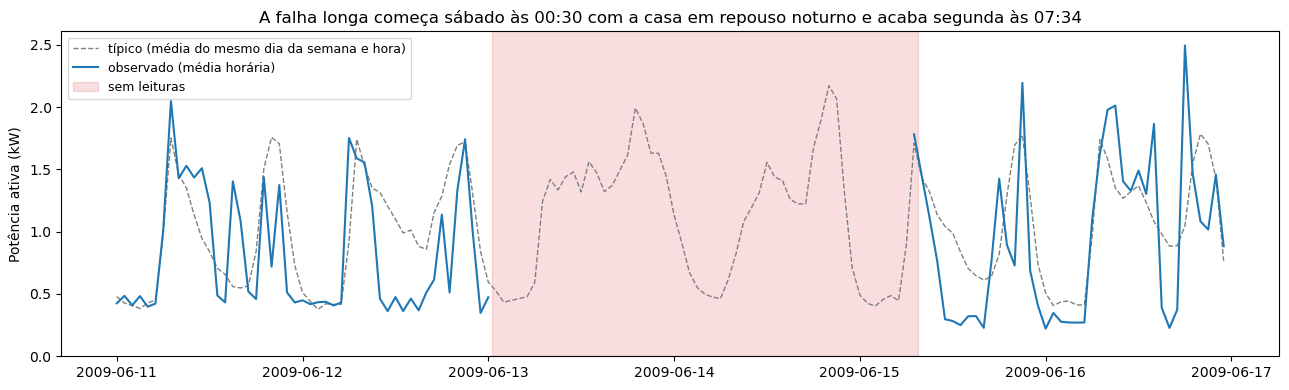

Últimos minutos antes da falha:
                     Global_active_power     Voltage  Sub_metering_3
instante                                                            
2009-06-13 00:25:00                0.322  241.309998             0.0
2009-06-13 00:26:00                0.340  241.380005             1.0
2009-06-13 00:27:00                0.338  241.589996             1.0
2009-06-13 00:28:00                0.340  241.559998             0.0
2009-06-13 00:29:00                0.340  241.399994             1.0

Primeiros minutos depois da falha:
                     Global_active_power     Voltage  Sub_metering_3
instante                                                            
2009-06-15 07:35:00                2.162  238.520004            25.0
2009-06-15 07:36:00                2.222  238.330002            29.0
2009-06-15 07:37:00                2.234  237.199997            29.0
2009-06-15 07:38:00                2.224  235.940002            29.0
2009-06-15 07:39:00                

In [12]:
# d) A falha longa (13 a 15/06/2009)

longa = lac.loc[lac['minutos'].idxmax()]
tipico = potencia.groupby([potencia.index.dayofweek, potencia.index.hour]).mean()
zoom = potencia.loc['2009-06-11':'2009-06-16'].resample('h').mean().to_frame('observado')
zoom['tipico'] = tipico.loc[list(zip(zoom.index.dayofweek, zoom.index.hour))].to_numpy()

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(zoom.index, zoom['tipico'], color='gray', ls='--', lw=1, label='típico (média do mesmo dia da semana e hora)')
ax.plot(zoom.index, zoom['observado'], color='tab:blue', label='observado (média horária)')
ax.axvspan(longa['inicio'], longa['fim'], color='tab:red', alpha=0.15, label='sem leituras')
ax.set_ylim(bottom=0)
ax.set_ylabel('Potência ativa (kW)')
ax.set_title('A falha longa começa sábado às 00:30 com a casa em repouso noturno e acaba segunda às 07:34')
ax.legend(loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

vizinhanca = ['Global_active_power', 'Voltage', 'Sub_metering_3']
print('Últimos minutos antes da falha:')
print(df.loc[longa['inicio'] - pd.Timedelta(minutes=5):longa['inicio'], vizinhanca].dropna().to_string())
print('\nPrimeiros minutos depois da falha:')
print(df.loc[longa['fim']:longa['fim'] + pd.Timedelta(minutes=5), vizinhanca].dropna().to_string())

segundas = df[df.index.dayofweek == 0].between_time('07:35', '07:44')['Sub_metering_3']
print(f'\nSub_metering_3 numa segunda-feira típica, 07:35 a 07:44: {segundas.mean():.1f} Wh/min')
print(f"Minutos da janela com Sub_metering_3 >= 25 Wh: {(df['Sub_metering_3'] >= 25).mean():.1%}")

R.: **Lacunas curtas (menos de 1 dia).** Na mediana, o minuto anterior à lacuna tem o consumo normal para aquela hora (razão de 1,08), o que é compatível com MCAR: uma falha de comunicação ao acaso. Mas 5 das 24 começam logo a seguir a um minuto acima de 3 kW, quando por acaso esperaríamos 1,3 (p = 0,009 numa binomial). Este p é otimista: escolhemos o limiar de 3 kW depois de olhar para os dados, e com 24 lacunas basta uma ou duas para mudar o resultado. É um indício, não uma conclusão, de que o registo falha mais em picos de carga. Se se confirmar, a falta depende de um valor observado (o minuto anterior), o que é MAR e não MCAR puro; e como o consumo ao minuto tem autocorrelação de 0,97, o valor em falta é provavelmente também alto. Para o tratamento isto pesa pouco, porque a interpolação usa precisamente os vizinhos, que já refletem esse pico. Para o CP2: repetir o teste, com o limiar fixado agora, nas lacunas fora da nossa janela, que não usámos para formular a hipótese.

**Falha longa (13 a 15/06/2009).** Não temos o consumo durante a falha, e as hipóteses levam a mecanismos diferentes:

- avaria do registador com a casa a funcionar normalmente: a falta não depende do consumo (MCAR em relação ao valor);
- família fora no fim de semana com o quadro desligado, ou corte de energia: o consumo em falta seria perto de zero, e a falta depende do próprio valor não observado (MNAR).

Os dados à volta não decidem. Antes da falha, a casa está no nível de repouso noturno (0,34 kW) e a tensão é normal (241 V), sem sinal de problema na rede. No regresso, o termoacumulador (Sub_metering_3) está a 25 a 30 Wh/min, contra uma média de 13 Wh/min numa segunda-feira típica a essa hora (valores de 25 Wh ou mais só aparecem em 0,8 % dos minutos da janela); é compatível com aquecer água que arrefeceu durante dois dias sem energia, mas também com um simples banho. Com um único caso não há forma de testar o mecanismo. Como não podemos excluir MNAR, tratamo-la como MNAR possível: se a casa estava vazia ou sem energia, qualquer imputação a partir do perfil típico inventa consumo que não existiu.

**Lacuna de 70 min (quarta 10/12/2008, 10:48 a 11:57).** Cai a meio de uma manhã de dia útil com consumo normal antes e depois (1,7 a 2,1 kW): parece uma falha do registo sem relação com o consumo, compatível com MCAR.

**e) Estratégia de tratamento**

A pergunta é até que duração vale a pena reconstruir uma lacuna. Para responder com os próprios dados, abrimos lacunas artificiais em troços completos da janela (500 por duração, seed fixa), tapamo-las com interpolação linear e comparamos o erro com duas alternativas: o perfil típico (média do mesmo dia da semana e hora) e a mediana global.

,interpolacao_linear,perfil_tipico,mediana_global
duracao_min,,,
1,0.068,0.640,0.753
2,0.069,0.625,0.725
5,0.104,0.613,0.681
10,0.188,0.658,0.741
30,0.286,0.650,0.769
60,0.372,0.644,0.741
180,0.495,0.607,0.699
720,0.757,0.618,0.718
1440,0.842,0.616,0.734


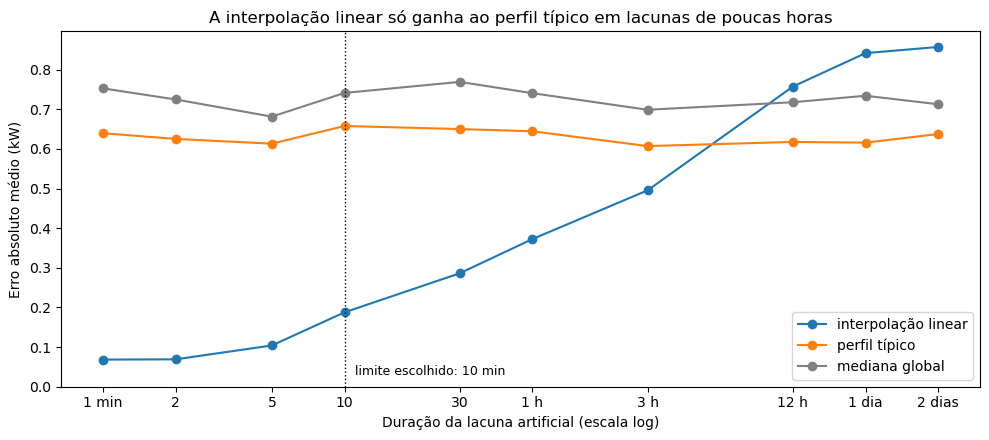

Consumo médio na janela: 1.05 kW


In [13]:
# e) Erro de reconstrução por duração da lacuna

def erro_reconstrucao(serie, duracoes, n=500, seed=SEED):
    rng = np.random.default_rng(seed)
    x = serie.to_numpy('float64')
    perfil = serie.groupby([serie.index.dayofweek, serie.index.hour]).transform('mean').to_numpy('float64')
    mediana = np.nanmedian(x)
    observado = pd.Series(serie.notna().to_numpy(dtype=float))
    linhas = []
    for L in duracoes:
        # inícios s possíveis: o troço [s-1, s+L] está todo observado
        inicios = np.flatnonzero(observado.rolling(L + 2).min().to_numpy() == 1) - L
        s = rng.choice(inicios, n, replace=False)
        pos = s[:, None] + np.arange(L)
        antes, depois = x[s - 1], x[s + L]
        interpolado = antes[:, None] + np.arange(1, L + 1) / (L + 1) * (depois - antes)[:, None]
        linhas.append({'duracao_min': L,
                       'interpolacao_linear': np.abs(interpolado - x[pos]).mean(),
                       'perfil_tipico': np.abs(perfil[pos] - x[pos]).mean(),
                       'mediana_global': np.abs(mediana - x[pos]).mean()})
    return pd.DataFrame(linhas).set_index('duracao_min')

erros = erro_reconstrucao(potencia, [1, 2, 5, 10, 30, 60, 180, 720, 1440, 2880])
display(erros.round(3))

fig, ax = plt.subplots(figsize=(10, 4.5))
nomes = ['interpolação linear', 'perfil típico', 'mediana global']
for coluna, nome, cor in zip(erros.columns, nomes, ['tab:blue', 'tab:orange', 'gray']):
    ax.plot(erros.index, erros[coluna], marker='o', color=cor, label=nome)
ax.axvline(10, color='black', ls=':', lw=1)
ax.text(11, 0.03, 'limite escolhido: 10 min', fontsize=9)
ax.set_xscale('log')
ax.xaxis.set_minor_locator(plt.NullLocator())
ax.set_xticks(erros.index, ['1 min', '2', '5', '10', '30', '1 h', '3 h', '12 h', '1 dia', '2 dias'])
ax.set_ylim(0, None)
ax.set_xlabel('Duração da lacuna artificial (escala log)')
ax.set_ylabel('Erro absoluto médio (kW)')
ax.set_title('A interpolação linear só ganha ao perfil típico em lacunas de poucas horas')
ax.legend()
plt.tight_layout()
plt.show()

print(f'Consumo médio na janela: {potencia.mean():.2f} kW')

R.: Até 10 minutos, a interpolação linear erra em média entre 0,07 e 0,19 kW por minuto, três a nove vezes menos do que o perfil típico (cerca de 0,63 kW), porque o consumo ao minuto muda devagar. A vantagem encolhe com a duração e desaparece entre 3 e 12 horas. Numa lacuna de 2 dias, a reta entre os dois extremos erra 0,86 kW, pior até do que usar sempre a mediana (0,71 kW). O perfil típico também não serve para 2 dias: erra cerca de 0,64 kW por minuto, 60 % do consumo médio, e assume que a casa estava ocupada, o que a hipótese MNAR põe em causa.

A decisão, por duração da lacuna:

| Lacuna | Na janela | Decisão | Porquê |
|---|---|---|---|
| 1 a 10 min | 20 lacunas, 36 min | interpolação linear no tempo | erro ≤ 0,19 kW; no pior caso preenche 1/6 da janela de 60 min da Parte IV, por isso não chega para fabricar um padrão |
| 11 min a 1 dia | 4 lacunas, 175 min | ficam NaN ao minuto; nos agregados entram só os minutos observados | uma reta de 1 h já esconde os ciclos dos aparelhos e falsearia variâncias e alarmes na Parte IV |
| mais de 1 dia | 1 lacuna, 3 305 min | não se imputa; os dias com menos de 90 % de cobertura saem das análises diárias | não há informação para reconstruir: mesmo o perfil típico erra cerca de 60 % do consumo médio, e o mecanismo pode ser MNAR |

A regra dos 90 % de cobertura aplica-se a todos os dias, qualquer que seja a lacuna; na nossa janela só os três dias da falha longa ficam abaixo (ver a aplicação a seguir).

O limite de 10 minutos é conservador: pelo teste, a interpolação continua a ganhar ao perfil até cerca de 3 horas, mas para a Parte IV interessa-nos não introduzir troços artificiais longos ao minuto.

In [14]:
# e) Aplicação

limpo = tratar_lacunas(df, max_minutos=10)
diario = consumo_diario(limpo, cobertura_min=0.9)

print(f"Minutos interpolados: {df['Global_active_power'].isna().sum() - limpo['Global_active_power'].isna().sum()}")
print(f"Minutos que ficam em falta: {limpo['Global_active_power'].isna().sum()}")
print(f"Dias válidos para análise diária: {diario['kWh'].notna().sum()} de {len(diario)}")
diario[diario['cobertura'] < 1].sort_values('cobertura').round(3)

Minutos interpolados: 36
Minutos que ficam em falta: 3480
Dias válidos para análise diária: 544 de 547


,kWh,cobertura
instante,,
2009-06-14,NaN,0.000
2009-06-13,NaN,0.021
2009-06-15,NaN,0.684
2008-12-10,36.981,0.951
2008-10-25,26.167,0.970
2009-02-01,30.941,0.974
2009-02-17,13.249,0.983


R.: A regra interpola 36 minutos, deixa 3 480 em falta e tira 3 dias das análises diárias (13, 14 e 15 de junho de 2009), ficando 544 de 547. O limiar de 90 % não é crítico: o dia mais incompleto que fica (10/12/2008, com a lacuna de 70 min) tem 95 % de cobertura e o mais completo que sai (15/06/2009) tem 68 %, por isso qualquer limiar entre 70 % e 95 % dá o mesmo resultado. Tirar o dia 15 também evita um enviesamento: as horas que lhe faltam são a madrugada (00:00 a 07:34), quando o consumo é baixo, e a média dos minutos observados sobrestimaria o consumo desse dia. Na Parte III, os lags que dependam destes dias ficam NaN em vez de serem inventados.

# Resumo para o Checkpoint 1

- **Dados:** 2 075 259 minutos carregados em menos de meio minuto, com tipos explícitos; janela do grupo de 01/02/2008 a 31/07/2009 (787 680 minutos).
- **Tipagem:** dicionário de dados com escala de Stevens; float32 justificado; 10 asserts, testados contra 5 versões estragadas dos dados.
- **Qualidade:** 0,45 % dos minutos em falta, sempre a linha inteira; 25 lacunas, uma delas (2,3 dias) com 94 % dos minutos em falta; 1 dia inteiro sem leituras.
- **Tratamento:** três regimes por duração da lacuna, com o limite de 10 min apoiado num teste de reconstrução.
- **Em aberto para o CP2:** sumário e outliers (1.3); confirmar o indício de falhas em picos de carga nas lacunas fora da nossa janela; decidir como tratar o possível desfasamento de hora de verão nos perfis horários.

# 1.3 Sumário estatístico com juízo (Checkpoint 2)

**1.3)** Sumário estatístico com juízo: para as variáveis principais, medidas de localização e dispersão adequadas à forma (justificar média vs mediana com assimetria), outliers pela regra 1,5×IQR **e** por z-score robusto (mediana/MAD), com investigação: os extremos são erros, eventos reais ou fraude potencial? Sumário estratificado obrigatório: consumo por hora do dia × dia da semana (pivot com n).

In [26]:
import matplotlib.dates as mdates

from src.dados import VARIAVEIS, SUBMEDICOES
from src.sumario import (resumo_forma, zscore_robusto, outliers_iqr, eventos, corridas_constantes,
                         mascara_corridas_constantes, pivot_hora_dia, p_binomial, dados_tratados)

pot = limpo['Global_active_power']

NOMES = {'Global_active_power': 'Potência ativa (kW)', 'Global_reactive_power': 'Potência reativa (kW)',
         'Voltage': 'Tensão (V)', 'Global_intensity': 'Intensidade (A)',
         'Sub_metering_1': 'Cozinha (Wh/min)', 'Sub_metering_2': 'Lavandaria (Wh/min)',
         'Sub_metering_3': 'Termoacumulador e ar cond. (Wh/min)'}

**a) Localização, dispersão e forma**

A medida de localização depende da forma: com assimetria, a média é puxada pela cauda e a mediana descreve melhor o valor típico. Usamos a assimetria (skewness) como critério: acima de 0,5 em valor absoluto escolhemos mediana + IQR; abaixo, média + desvio-padrão. O MAD é a dispersão robusta (mediana dos desvios absolutos à mediana).

In [27]:
# a) Sumário por variável

forma = resumo_forma(limpo)
forma.round(3)

,n,media,mediana,desvio,mad,iqr,assimetria,curtose_excesso,%_zeros,medida_adequada
Global_active_power,784200,1.049916,0.558,1.025506,0.35,1.184,1.868829,4.71476,0.0,mediana + IQR
Global_reactive_power,784200,0.120231,0.098,0.110806,0.086,0.142,1.308156,2.877137,23.834353,mediana + IQR
Voltage,784200,241.118848,241.139999,2.952381,1.809998,3.619995,-0.250346,1.107437,0.0,média + desvio
Global_intensity,784200,4.448889,2.4,4.302766,1.6,4.8,1.927975,5.10092,0.0,mediana + IQR
Sub_metering_1,784200,1.093046,0.0,6.104141,0.0,0.0,5.993627,35.870419,91.919408,mediana + IQR
Sub_metering_2,784200,1.206496,0.0,5.62651,0.0,1.0,7.371725,62.635687,72.630196,mediana + IQR
Sub_metering_3,784200,6.233815,1.0,8.32821,1.0,17.0,0.795187,-1.166431,39.515685,mediana + IQR


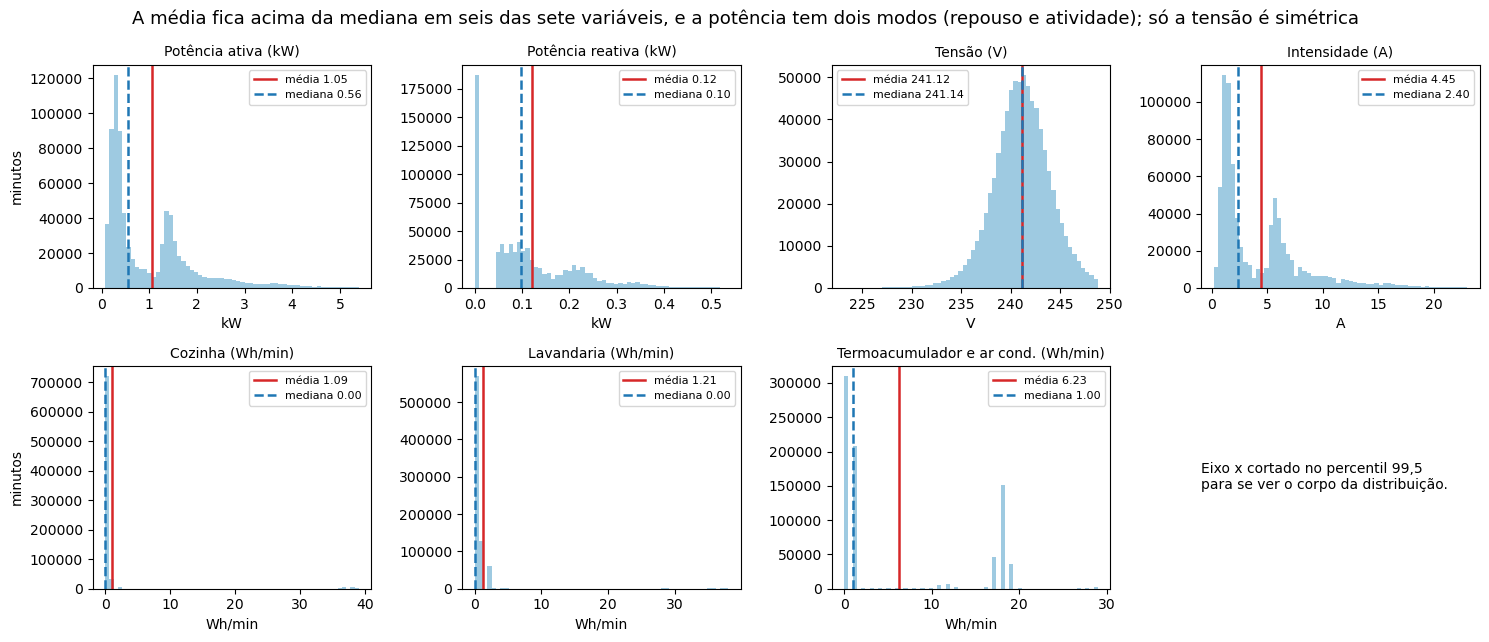

In [28]:
# b) A forma das distribuições

fig, eixos = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, v in zip(eixos.ravel(), VARIAVEIS):
    x = limpo[v].dropna()
    ax.hist(x, bins=60, range=(x.min(), x.quantile(0.995)), color='#9ecae1')
    ax.axvline(x.mean(), color='tab:red', lw=1.8, label=f'média {x.mean():.2f}')
    ax.axvline(x.median(), color='tab:blue', lw=1.8, ls='--', label=f'mediana {x.median():.2f}')
    ax.set_title(NOMES[v], fontsize=10)
    ax.legend(fontsize=8)
    ax.set_xlabel(NOMES[v].split('(')[1][:-1] if '(' in NOMES[v] else '')
for ax in eixos[:, 0]:
    ax.set_ylabel('minutos')
eixos[1, 3].axis('off')
eixos[1, 3].text(0, 0.5, 'Eixo x cortado no percentil 99,5\npara se ver o corpo da distribuição.', fontsize=10, va='center')
fig.suptitle('A média fica acima da mediana em seis das sete variáveis, e a potência tem dois modos (repouso e atividade); só a tensão é simétrica', fontsize=13)
plt.tight_layout()
plt.show()

R.: Seis das sete variáveis têm a média acima da mediana (assimetria entre 0,80 e 7,37). Na potência ativa a média é 1,05 kW e a mediana 0,56 kW (assimetria 1,87), e o histograma mostra porquê: há dois modos, um de repouso, perto de 0,3 kW, e outro de atividade, perto de 1,4 kW, mais uma cauda longa até 11 kW. A média cai entre os dois modos e não descreve nenhum estado da casa, por isso para o minuto típico usamos a mediana (0,56 kW, com IQR de 1,18 kW) e a média só para somar energia (consumo diário em kWh = média × 24 h).

A tensão é a exceção: média 241,12 V, mediana 241,14 V e assimetria −0,25, por isso média e desvio-padrão (2,95 V) servem. Nas submedições o centro engana: Sub_metering_1 tem 91,9 % de zeros e Sub_metering_2 72,6 % (mediana 0 e MAD 0), pelo que o que as caracteriza é a fração de minutos ligados e o que gastam quando ligam. Sub_metering_3 é bimodal (39,5 % de zeros e um segundo grupo perto de 18 Wh/min, curtose −1,17): nem a mediana (1) nem a média (6,2) são valores que o aparelho tenha de facto. A regra da assimetria manda usar mediana + IQR em seis variáveis, mas em duas delas o número sozinho não basta e o histograma tem de o acompanhar.

**c) Outliers: 1,5×IQR e z-score robusto**

O z-score robusto usa `0,6745 × (x − mediana) / MAD` e marca como outlier |z| > 3,5. Aplicamos as duas regras às sete variáveis. Se o MAD for 0 (mais de metade dos valores iguais), o z-score robusto não está definido.

,limite_sup_IQR,MAD,n_IQR,%_IQR,n_z,%_z,n_ambos
Global_active_power,3.268,0.350,34995,4.463,77563,9.891,34995
Global_reactive_power,0.403,0.086,15577,1.986,3622,0.462,3622
Voltage,248.400,1.810,16788,2.141,4565,0.582,4565
Global_intensity,13.400,1.600,37092,4.730,66667,8.501,37092
Sub_metering_1,0.000,0.000,63368,8.081,0,0.000,0
Sub_metering_2,2.500,0.000,27374,3.491,0,0.000,0
Sub_metering_3,42.500,1.000,0,0.000,262688,33.498,0


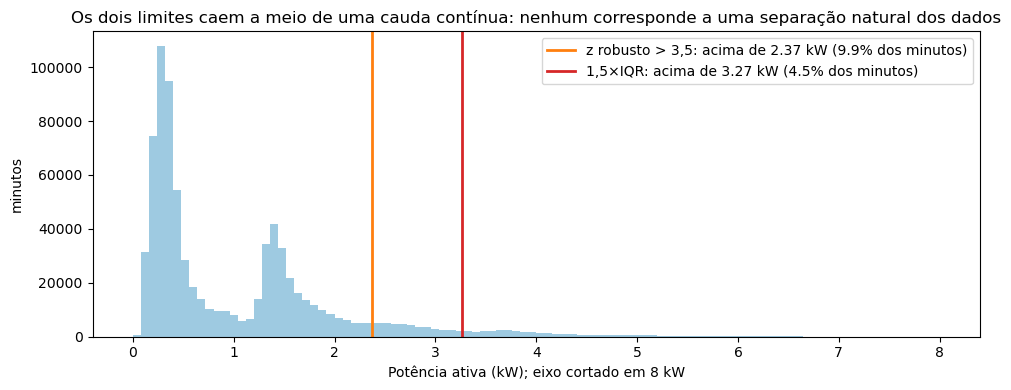

In [18]:
# c) Quantos outliers dá cada regra?

linhas = {}
for v in VARIAVEIS:
    x = limpo[v].dropna()
    q1, q3 = x.quantile([0.25, 0.75])
    por_iqr = outliers_iqr(x)
    por_z = zscore_robusto(x).abs() > 3.5
    linhas[v] = {'limite_sup_IQR': q3 + 1.5 * (q3 - q1), 'MAD': (x - x.median()).abs().median(),
                 'n_IQR': por_iqr.sum(), '%_IQR': 100 * por_iqr.mean(),
                 'n_z': por_z.sum(), '%_z': 100 * por_z.mean(), 'n_ambos': (por_iqr & por_z).sum()}
outliers = pd.DataFrame(linhas).T.astype({'n_IQR': int, 'n_z': int, 'n_ambos': int})
display(outliers.round(3))

x = pot.dropna()
mediana, mad = x.median(), (x - x.median()).abs().median()
lim_iqr = x.quantile(0.75) + 1.5 * (x.quantile(0.75) - x.quantile(0.25))
lim_z = mediana + 3.5 * mad / 0.6745

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(x, bins=100, range=(0, 8), color='#9ecae1')
ax.axvline(lim_z, color='tab:orange', lw=2, label=f'z robusto > 3,5: acima de {lim_z:.2f} kW ({(x > lim_z).mean():.1%} dos minutos)')
ax.axvline(lim_iqr, color='tab:red', lw=2, label=f'1,5×IQR: acima de {lim_iqr:.2f} kW ({(x > lim_iqr).mean():.1%} dos minutos)')
ax.set_xlabel('Potência ativa (kW); eixo cortado em 8 kW')
ax.set_ylabel('minutos')
ax.set_title('Os dois limites caem a meio de uma cauda contínua: nenhum corresponde a uma separação natural dos dados')
ax.legend()
plt.tight_layout()
plt.show()

R.: Na potência ativa as duas regras discordam. O 1,5×IQR marca 34 995 minutos (4,5 %), acima de 3,27 kW; o z-score robusto marca 77 563 (9,9 %), acima de 2,37 kW, e inclui todos os do IQR. O z é mais severo porque o MAD é pequeno (0,35 kW): a casa passa muito tempo em repouso, e qualquer atividade normal fica "longe" da mediana. A figura mostra que nenhum dos dois limites corresponde a uma separação natural dos dados: ambos caem a meio de uma cauda contínua.

Nas outras variáveis as regras falham de formas diferentes. Na tensão e na potência reativa acontece o inverso da potência ativa (o IQR marca mais do que o z: 2,1 % contra 0,6 % e 2,0 % contra 0,5 %). Em Sub_metering_1, Q1 = Q3 = 0, por isso o IQR é 0 e qualquer minuto com a cozinha ligada (8,1 %) é outlier, enquanto o MAD também é 0 e o z-score nem está definido. Em Sub_metering_3 dá-se o oposto: o z-score marca 33,5 % dos minutos, todo o modo "ligado" (o MAD é 1 Wh/min), e o IQR não marca nenhum. Nenhuma das regras distingue erro de consumo real, por isso não removemos outliers por regra estatística: usamo-las só para escolher candidatos a investigar (d).

**d) Investigação dos extremos.** Três perguntas, uma por tipo de suspeita: os picos de potência são consumo real? Há leituras que parecem erro ou fraude? Há dias inteiros fora do normal?

In [29]:
# d) 1. Os picos de potência: o que é que estava ligado?

limiar = pot.quantile(0.999)
picos = eventos(pot > limiar, '30min')
picos['max_kW'] = [pot.loc[a:b].max() for a, b in zip(picos['inicio'], picos['fim'])]
picos['duracao_min'] = ((picos['fim'] - picos['inicio']).dt.total_seconds() / 60 + 1).astype(int)
for s in SUBMEDICOES:
    picos[s] = [limpo[s].loc[a:b].mean() for a, b in zip(picos['inicio'], picos['fim'])]
picos['dia_semana'] = [DIAS[d] for d in picos['inicio'].dt.dayofweek]

print(f'{len(picos)} eventos com minutos acima de {limiar:.2f} kW (percentil 99,9)')
print('Por dia da semana:', picos['dia_semana'].value_counts().reindex(DIAS).to_dict())
print('Início às 6 h:', (picos['inicio'].dt.hour == 6).sum(), '| às 20 h:', (picos['inicio'].dt.hour == 20).sum())
print('\nSub_metering_x = média em Wh/min durante o evento (1 kW = 16,7 Wh/min)')
picos.nlargest(8, 'max_kW')[['inicio', 'dia_semana', 'duracao_min', 'max_kW'] + SUBMEDICOES].round({'max_kW': 1, **{s: 1 for s in SUBMEDICOES}}).reset_index(drop=True)

133 eventos com minutos acima de 6.71 kW (percentil 99,9)
Por dia da semana: {'segunda': 7, 'terça': 27, 'quarta': 14, 'quinta': 9, 'sexta': 10, 'sábado': 31, 'domingo': 35}
Início às 6 h: 16 | às 20 h: 23

Sub_metering_x = média em Wh/min durante o evento (1 kW = 16,7 Wh/min)


,inicio,dia_semana,duracao_min,max_kW,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,2009-02-22 16:55:00,domingo,33,11.1,15.500000,53.500000,16.799999
1,2008-11-30 20:10:00,domingo,20,10.3,24.200001,53.599998,16.799999
2,2008-10-19 00:43:00,domingo,51,10.3,13.700000,33.700001,18.500000
3,2009-01-25 13:26:00,domingo,11,9.6,36.500000,72.300003,17.000000
4,2008-04-12 18:07:00,sábado,37,9.5,29.799999,31.000000,17.799999
5,2008-05-20 12:10:00,terça,14,8.9,28.700001,65.300003,16.900000
6,2008-11-05 13:32:00,quarta,9,8.9,20.600000,69.400002,17.000000
7,2009-01-10 19:51:00,sábado,14,8.8,25.100000,71.400002,16.600000


R.: Há 133 eventos com minutos acima de 6,71 kW (percentil 99,9) e não parecem erros. Concentram-se no fim de semana e à terça (31 ao sábado, 35 ao domingo e 27 à terça, em 133) e ao fim do dia (23 começam às 20 h); 16 começam às 6 h, a hora em que sobe o consumo matinal (ver e). Nos oito maiores, o circuito da lavandaria (Sub_metering_2) gasta de 31 a 72 Wh/min, isto é, de 1,9 a 4,3 kW, e o termoacumulador (Sub_metering_3) está sempre a cerca de 17 Wh/min (1 kW): são vários aparelhos grandes ligados ao mesmo tempo. Conclusão: os picos são consumo real e ficam nos dados.

Corridas de 30 ou mais minutos com as 7 variáveis idênticas na janela:


,inicio,fim,minutos
0,2008-10-06 10:09:00,2008-10-06 16:48:00,400


No conjunto completo (4 anos): 1


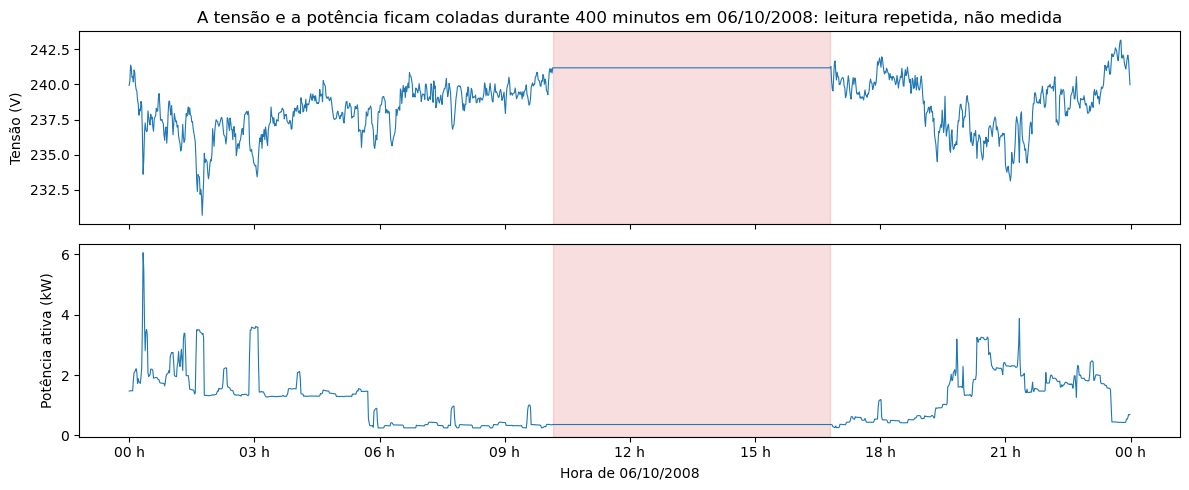

In [30]:
# d) 2. Leituras repetidas: há minutos em que as 7 variáveis ficam coladas?

colados = corridas_constantes(limpo, minimo=30)
print('Corridas de 30 ou mais minutos com as 7 variáveis idênticas na janela:')
display(colados)
print(f'No conjunto completo (4 anos): {len(corridas_constantes(completo, minimo=30))}')

dia = colados.loc[0, 'inicio'].normalize()
sinal = limpo.loc[dia:dia + pd.Timedelta(hours=23, minutes=59)]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
ax1.plot(sinal.index, sinal['Voltage'], color='tab:blue', lw=0.8)
ax1.set_ylabel('Tensão (V)')
ax2.plot(sinal.index, sinal['Global_active_power'], color='tab:blue', lw=0.8)
ax2.set_ylabel('Potência ativa (kW)')
for ax in (ax1, ax2):
    ax.axvspan(colados.loc[0, 'inicio'], colados.loc[0, 'fim'], color='tab:red', alpha=0.15)
ax1.set_title(f'A tensão e a potência ficam coladas durante {colados.loc[0, "minutos"]} minutos em {dia:%d/%m/%Y}: leitura repetida, não medida')
ax2.set_xlabel(f'Hora de {dia:%d/%m/%Y}')
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%H h'))
plt.tight_layout()
plt.show()

R.: Há uma única corrida de leituras coladas: 400 minutos seguidos (06/10/2008, das 10:09 às 16:48) com as 7 variáveis exatamente iguais, incluindo a tensão, que antes e depois oscila vários volts (gráfico). No conjunto completo, com quatro anos de dados, não há outra corrida de 30 ou mais minutos assim. A potência colada (0,36 kW) é um valor plausível, e é isso que a torna perigosa: sem olhar para a tensão passaria por uma manhã calma e entraria no consumo diário como se fosse medida.

Não conseguimos distinguir uma avaria do registador, que repete a última leitura, de uma cópia deliberada de valores (fraude potencial); em ambos os casos não são medições. Decisão: anulamos os 400 minutos (ficam NaN, sem interpolar, porque 400 minutos é muito mais do que os 10 minutos do limite de 1.2e). O dia 06/10/2008 fica com 72 % de cobertura e sai das análises diárias pela regra dos 90 %.

Minutos anulados: 400
Dias válidos para análise diária: 543 de 547
Dias fora (cobertura < 90 %): 06/10/2008, 13/06/2009, 14/06/2009, 15/06/2009

Dias com |z| > 3,5: 3 acima e 0 abaixo da mediana (25.6 kWh)
Limite inferior do z robusto: -3.3 kWh (MAD = 5.6 kWh)


,kWh,dia_semana
instante,,
2008-11-23,56.8,domingo
2009-01-17,55.3,sábado
2009-01-31,55.2,sábado



41 dias abaixo de 10 kWh (mediana 25.6 kWh), em 9 períodos:


,inicio,fim,dias,kWh_medio
0,2008-02-25,2008-02-28,4,8.7
1,2008-05-01,2008-05-01,1,9.6
2,2008-08-02,2008-08-03,2,8.4
3,2008-08-06,2008-08-30,25,4.8
4,2008-10-26,2008-10-27,2,8.7
5,2008-12-29,2008-12-29,1,9.3
6,2009-07-12,2009-07-13,2,8.4
7,2009-07-16,2009-07-16,1,10.0
8,2009-07-24,2009-07-26,3,9.1


z robusto de 23/08/2008 (4,2 kWh): -2.59


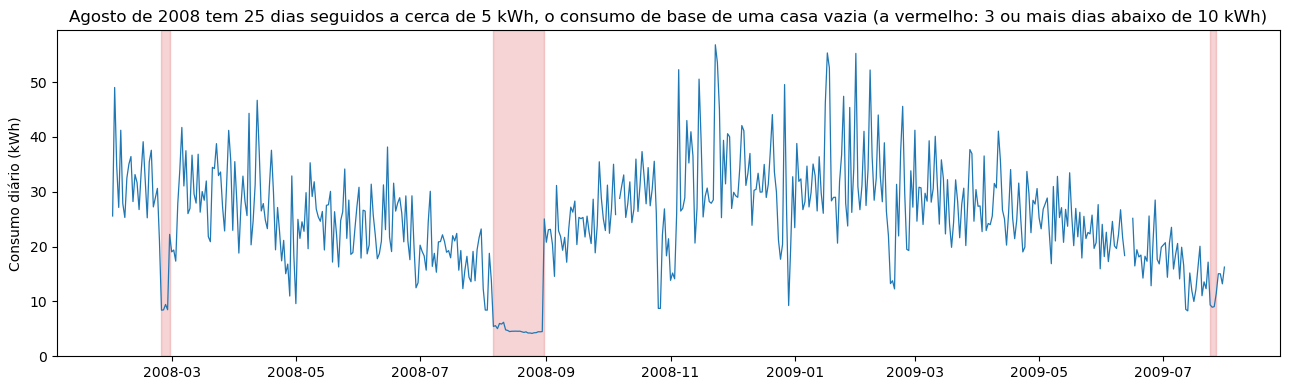

In [33]:
# d) 3. Tratamento da corrida colada e dias extremos

tratado = dados_tratados(df)   # tratar_lacunas(df, 10) + anular as corridas coladas
diario_ok = consumo_diario(tratado, cobertura_min=0.9)
kwh = diario_ok['kWh']

print(f"Minutos anulados: {limpo['Global_active_power'].notna().sum() - tratado['Global_active_power'].notna().sum()}")
print(f'Dias válidos para análise diária: {kwh.notna().sum()} de {len(kwh)}')
print(f"Dias fora (cobertura < 90 %): {', '.join(diario_ok.index[diario_ok['cobertura'] < 0.9].strftime('%d/%m/%Y'))}")

# z-score robusto sobre o consumo diário
z_dia = zscore_robusto(kwh.dropna())
mad_dia = (kwh - kwh.median()).abs().median()
print(f"\nDias com |z| > 3,5: {(z_dia > 3.5).sum()} acima e {(z_dia < -3.5).sum()} abaixo da mediana ({kwh.median():.1f} kWh)")
print(f"Limite inferior do z robusto: {kwh.median() - 3.5 * mad_dia / 0.6745:.1f} kWh (MAD = {mad_dia:.1f} kWh)")
display(kwh[z_dia.abs().gt(3.5).reindex(kwh.index, fill_value=False)].round(1).to_frame('kWh').assign(dia_semana=lambda d: [DIAS[i] for i in d.index.dayofweek]))

# dias muito abaixo do normal, agrupados em períodos
baixos = (kwh < 10).fillna(False)
periodos = eventos(baixos, '1D')
periodos['dias'] = periodos['n_true']
periodos['kWh_medio'] = [kwh.loc[a:b][baixos.loc[a:b]].mean() for a, b in zip(periodos['inicio'], periodos['fim'])]
print(f'\n{baixos.sum()} dias abaixo de 10 kWh (mediana {kwh.median():.1f} kWh), em {len(periodos)} períodos:')
display(periodos[['inicio', 'fim', 'dias', 'kWh_medio']].round({'kWh_medio': 1}))
print(f"z robusto de 23/08/2008 (4,2 kWh): {z_dia.loc['2008-08-23']:.2f}")

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(kwh.index, kwh, color='tab:blue', lw=0.9)
for a, b, n in zip(periodos['inicio'], periodos['fim'], periodos['dias']):
    if n >= 3:
        ax.axvspan(a, b + pd.Timedelta(days=1), color='tab:red', alpha=0.2)
ax.set_ylim(bottom=0)
ax.set_ylabel('Consumo diário (kWh)')
ax.set_title('Agosto de 2008 tem 25 dias seguidos a cerca de 5 kWh, o consumo de base de uma casa vazia (a vermelho: 3 ou mais dias abaixo de 10 kWh)')
plt.tight_layout()
plt.show()

R.: **Dias muito acima do normal.** O z-score robusto marca 3 dias, todos da época fria e todos acima de 55 kWh, perto do dobro da mediana (25,6 kWh): domingo 23/11/2008 (56,8 kWh), sábado 17/01/2009 (55,3) e sábado 31/01/2009 (55,2). São dias de fim de semana, compatíveis com a casa em uso intenso e aquecimento. Para o confirmar faltam as temperaturas (dado externo), por isso é uma hipótese e não uma conclusão.

**Dias muito abaixo do normal.** O z-score não marca nenhum, mas há 41 dias abaixo de 10 kWh, em 9 períodos, e o maior tem 25 dias seguidos (6 a 30/08/2008) com média de 4,8 kWh por dia, ou seja, cerca de 0,2 kW de consumo de base (frigorífico, stand-by): a casa parece vazia, em linha com agosto, o mês típico de férias em França. A regra não os apanha porque o MAD diário é grande e o limite inferior do z robusto fica abaixo de 0 kWh, pelo que nenhum dia podia ser marcado por baixo: um estado que dura semanas não é um outlier pontual, é outro regime da casa. Há ainda períodos de 3 a 4 dias (25 a 28/02/2008 e 24 a 26/07/2009). Nada disto é erro, e é matéria-prima para a pergunta livre (detetar ausências automaticamente).

**e) Sumário estratificado: hora do dia × dia da semana**

Usamos a versão `tratado` (sem a corrida colada). Cada célula da tabela é a média da potência ativa nos minutos com leitura dessa hora e desse dia da semana, e o `n` diz em quantos minutos assenta.

n por célula: mínimo 4588, máximo 4740 minutos (cada dia da semana aparece cerca de 78 vezes na janela)


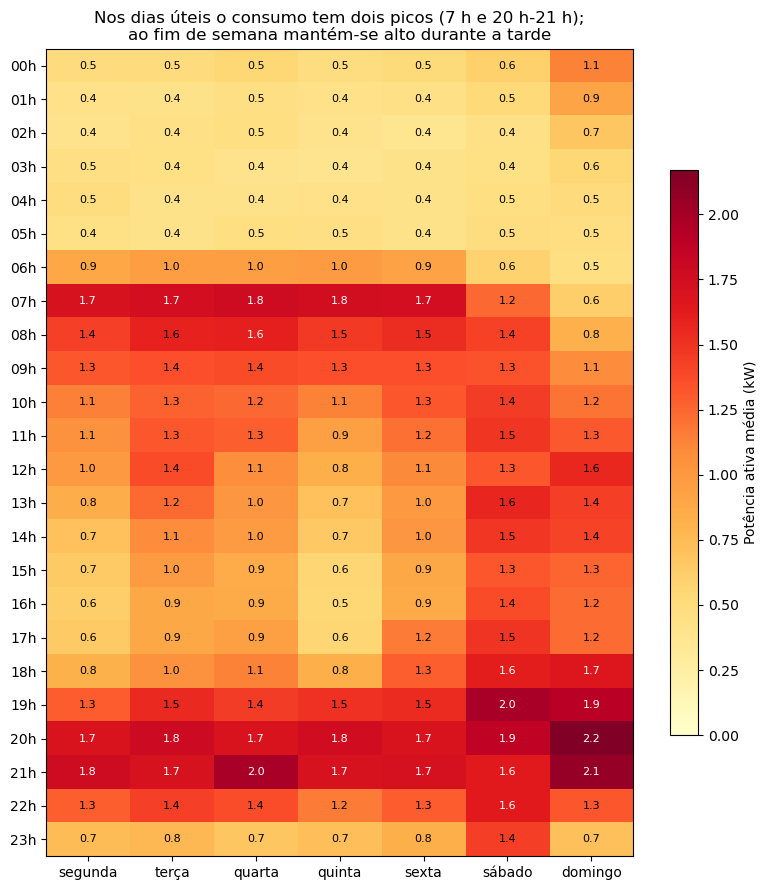

,segunda,terça,quarta,quinta,sexta,sábado,domingo
hora,,,,,,,
0,4620,4680,4680,4680,4740,4650,4620
1,4620,4680,4680,4680,4740,4620,4620
2,4620,4680,4680,4680,4740,4620,4620
3,4620,4680,4680,4680,4740,4620,4620
4,4620,4680,4680,4680,4740,4620,4620
5,4620,4680,4680,4680,4740,4620,4620
6,4620,4680,4680,4680,4740,4620,4620
7,4645,4680,4680,4680,4740,4620,4620
8,4680,4680,4680,4680,4740,4620,4620


In [22]:
# e) Pivot hora × dia da semana, com n

media, n = pivot_hora_dia(tratado['Global_active_power'])
media.columns = DIAS
n.columns = DIAS

print(f'n por célula: mínimo {n.min().min()}, máximo {n.max().max()} minutos (cada dia da semana aparece cerca de 78 vezes na janela)')

fig, ax = plt.subplots(figsize=(8, 9))
im = ax.imshow(media, cmap='YlOrRd', aspect='auto', vmin=0)
ax.set_xticks(range(7), DIAS)
ax.set_yticks(range(24), [f'{h:02d}h' for h in range(24)])
for i in range(24):
    for j in range(7):
        ax.text(j, i, f'{media.iloc[i, j]:.1f}', ha='center', va='center', fontsize=8,
                color='white' if media.iloc[i, j] > 1.6 else 'black')
ax.set_title('Nos dias úteis o consumo tem dois picos (7 h e 20 h-21 h);\nao fim de semana mantém-se alto durante a tarde', fontsize=12)
fig.colorbar(im, label='Potência ativa média (kW)', shrink=0.7)
plt.tight_layout()
plt.show()

display(n)

R.: A tabela tem entre 4 588 e 4 740 minutos por célula (cada dia da semana aparece 77 a 79 vezes), por isso as diferenças entre células não vêm de falta de dados. Nos dias úteis há dois picos: às 7 h (1,7 a 1,8 kW) e entre as 20 h e as 21 h (1,7 a 2,0 kW), com um vale a meio da tarde, mais fundo à segunda e à quinta (0,5 a 0,7 kW entre as 14 h e as 17 h, o mais baixo da semana). Ao fim de semana o pico das 7 h desaparece (1,2 kW ao sábado, 0,6 kW ao domingo), a manhã sobe devagar e a tarde mantém-se entre 1,2 e 1,6 kW, cerca do dobro de segunda e quinta. O máximo da tabela é domingo às 20 h (2,2 kW). A madrugada é igual em todos os dias (0,4 a 0,5 kW), exceto de sábado para domingo, entre as 0 h e as 2 h (1,1 a 0,7 kW). Estes perfis alimentam a PCA da Parte II.

# Pendentes do Checkpoint 1

O resumo do CP1 deixou duas questões em aberto, resolvidas aqui: confirmar nas lacunas fora da nossa janela o indício de falhas em picos de carga, e decidir se a hora de verão desfasa os perfis horários.

In [23]:
# Pendente 1: as lacunas curtas começam a seguir a picos? (hipótese e limiar de 3 kW fixados no CP1, na janela)

potencia_total = completo['Global_active_power']
lac_todas = lacunas(completo)
fora = lac_todas[((lac_todas['inicio'] < inicio) | (lac_todas['inicio'] >= fim)) & (lac_todas['minutos'] < 1440)]

antes_fora = potencia_total.shift(1).loc[fora['inicio']].dropna()
fora_janela = (potencia_total.index < inicio) | (potencia_total.index >= fim)
n, k, p = len(antes_fora), int((antes_fora > 3).sum()), (potencia_total[fora_janela] > 3).mean()

print(f'Lacunas curtas fora da janela: {len(fora)} (com minuto anterior observado: {n})')
print(f'Começam a seguir a um minuto acima de 3 kW: {k} de {n} (por acaso esperaríamos {n * p:.1f})')
print(f'Minutos acima de 3 kW fora da janela: {p:.1%} | P(X >= {k}) numa binomial(n={n}, p={p:.3f}) = {p_binomial(n, k, p):.3f}')

Lacunas curtas fora da janela: 41 (com minuto anterior observado: 41)
Começam a seguir a um minuto acima de 3 kW: 7 de 41 (por acaso esperaríamos 2.6)
Minutos acima de 3 kW fora da janela: 6.4% | P(X >= 7) numa binomial(n=41, p=0.064) = 0.014


R.: Confirma-se. Fora da janela, 7 de 41 lacunas curtas (17 %) começam logo a seguir a um minuto acima de 3 kW, quando por acaso esperaríamos 2,6 (6,4 % dos minutos estão acima de 3 kW), com p = 0,014. Na janela eram 5 de 24 (p = 0,009), mas aí o limiar tinha sido escolhido depois de ver os dados; agora estava fixado de antemão e o teste usa dados que não serviram para formular a hipótese, com o mesmo sentido.

Continua a ser uma amostra pequena (41 lacunas), por isso concluímos com cautela: o registador parece falhar mais vezes logo a seguir a picos de carga. Se for assim, a falta depende do minuto anterior, que observamos (MAR), e não é MCAR puro. Para o tratamento o efeito é pequeno: a interpolação das lacunas curtas usa o minuto anterior e o seguinte, que já refletem o pico, e na janela só interpolamos 36 minutos.

In [24]:
# Pendente 2: a hora de verão desfasa os perfis horários?
# Se o registador estivesse fixo e a família seguisse a hora legal, a rotina saltaria ±60 min nas mudanças de hora.

def perfil_diario(serie):
    uteis = serie[serie.index.dayofweek < 5]
    perfil = uteis.groupby(uteis.index.hour * 60 + uteis.index.minute).mean()
    return perfil.rolling(30, center=True, min_periods=1).mean()

def desfasamento(a, b, passo=5, maximo=180):
    # minutos que é preciso atrasar o perfil b para ficar alinhado com o perfil a (máxima correlação)
    return max(range(-maximo, maximo + 1, passo),
               key=lambda m: np.corrcoef(a.to_numpy(), np.roll(b.to_numpy(), m))[0, 1])

comparacoes = [('mudança para a hora de verão', '2008-03-30'), ('mudança para a hora de inverno', '2008-10-26'),
               ('mudança para a hora de verão', '2009-03-29'),
               ('controlo (sem mudança)', '2008-05-05'), ('controlo (sem mudança)', '2008-12-01'),
               ('controlo (sem mudança)', '2009-05-04')]
linhas = []
for tipo, data in comparacoes:
    d = pd.Timestamp(data)
    antes_d = tratado['Global_active_power'][d - pd.Timedelta(days=28):d]
    depois_d = tratado['Global_active_power'][d + pd.Timedelta(days=1):d + pd.Timedelta(days=29)]
    linhas.append({'comparação': tipo, 'data': data, 'desfasamento_min': desfasamento(perfil_diario(antes_d), perfil_diario(depois_d))})
pd.DataFrame(linhas)

,comparação,data,desfasamento_min
0,mudança para a hora de verão,2008-03-30,-15
1,mudança para a hora de inverno,2008-10-26,5
2,mudança para a hora de verão,2009-03-29,-5
3,controlo (sem mudança),2008-05-05,5
4,controlo (sem mudança),2008-12-01,0
5,controlo (sem mudança),2009-05-04,-10


R.: Nas três mudanças de hora da janela, o perfil dos dias úteis das 4 semanas seguintes só precisa de ser deslocado −15, +5 e −5 minutos para se alinhar com o das 4 semanas anteriores. Nas comparações de controlo, sem mudança de hora, o resultado é +5, 0 e −10 minutos. Se o registador estivesse fixo e a família seguisse a hora legal, esperaríamos 60 minutos (para a frente na primavera, para trás no outono), e o desfasamento observado não se distingue do ruído dos controlos.

Conclusão: os perfis horários não precisam de correção, porque a rotina da família não salta uma hora nas datas de mudança. Isto não confirma a preocupação levantada em 1.1 e), e não sabemos explicar porquê (por exemplo, a hora de verão pode já vir aplicada na origem dos dados). Para a Parte II basta que a hora registada seja a hora a que a família vive. Limitação: o teste assume rotinas estáveis nas semanas antes e depois, e a luz natural também muda nesses períodos, o que o enviesaria no máximo em alguns minutos.

# Resumo da Parte I do Checkpoint 2

- **Sumário (1.3):** seis das sete variáveis têm média acima da mediana; a potência ativa tem dois modos (repouso e atividade) e usa-se a mediana (0,56 kW) como valor típico; só a tensão é simétrica.
- **Outliers:** o 1,5×IQR marca 4,5 % dos minutos de potência e o z robusto 9,9 %, sem corte natural nos dados. As regras não separam erro de consumo, por isso só servem para escolher candidatos.
- **Investigação:** os 133 picos acima de 6,71 kW são consumo real (lavandaria + termoacumulador). Há **uma** corrida de 400 minutos com as 7 variáveis coladas (06/10/2008), anulada. 25 dias seguidos de agosto de 2008 a 4,8 kWh/dia indicam casa vazia.
- **Pivot hora × dia da semana:** dois picos nos dias úteis (7 h e 20-21 h), tarde alta ao fim de semana, 4 588 a 4 740 minutos por célula.
- **Pendentes do CP1:** o indício de falhas em picos de carga confirma-se fora da janela (7 de 41, p = 0,014); a hora de verão não desfasa os perfis (−15 a +5 min, como nos controlos).
- **Dados a usar daqui para a frente:** `tratado = dados_tratados(df)` (em `src/sumario.py`) e `consumo_diario(tratado)`, com 543 dias válidos de 547.
- **Para o CP2:** pergunta livre candidata, a deteção automática de ausências (agosto de 2008, 25 a 28/02/2008, 24 a 26/07/2009); depois a Parte II (figuras, PCA, t-SNE/UMAP).